In [ ]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import sklearn as skl
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.applications import ResNet50
import os

In [ ]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

base_dir = '/content/drive/MyDrive/pneumonia_project/chest_xray_data/chest_xray'

Mounted at /content/drive


In [ ]:


for split in ['train', 'val', 'test']:
    for label in ['NORMAL', 'PNEUMONIA']:
        path = os.path.join(base_dir, split, label)
        count = len(os.listdir(path))
        print(f"{split}/{label}: {count} images")

train/NORMAL: 1341 images
train/PNEUMONIA: 3875 images
val/NORMAL: 8 images
val/PNEUMONIA: 8 images
test/NORMAL: 234 images
test/PNEUMONIA: 390 images


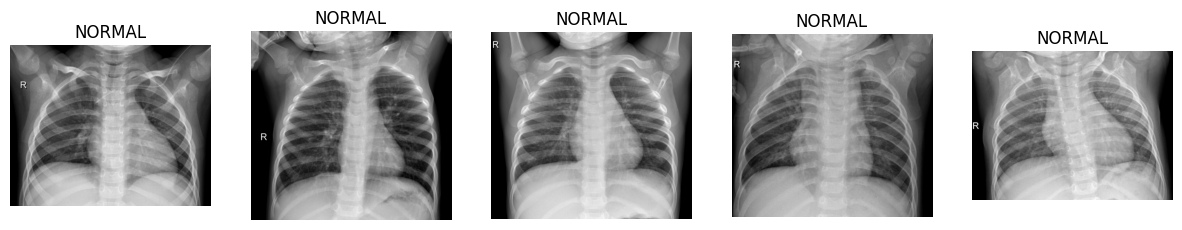

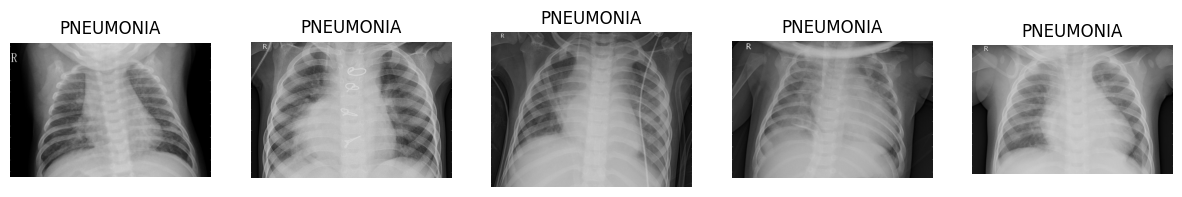

In [ ]:
def show_samples(label, n=5):
    path = os.path.join(base_dir, 'train', label)
    images = os.listdir(path)[:n]

    fig, axes = plt.subplots(1, n, figsize=(15, 5))
    for i, img_name in enumerate(images):
        img_path = os.path.join(path, img_name)
        img = plt.imread(img_path)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(label)
        axes[i].axis('off')
    plt.show()

show_samples('NORMAL')
show_samples('PNEUMONIA')

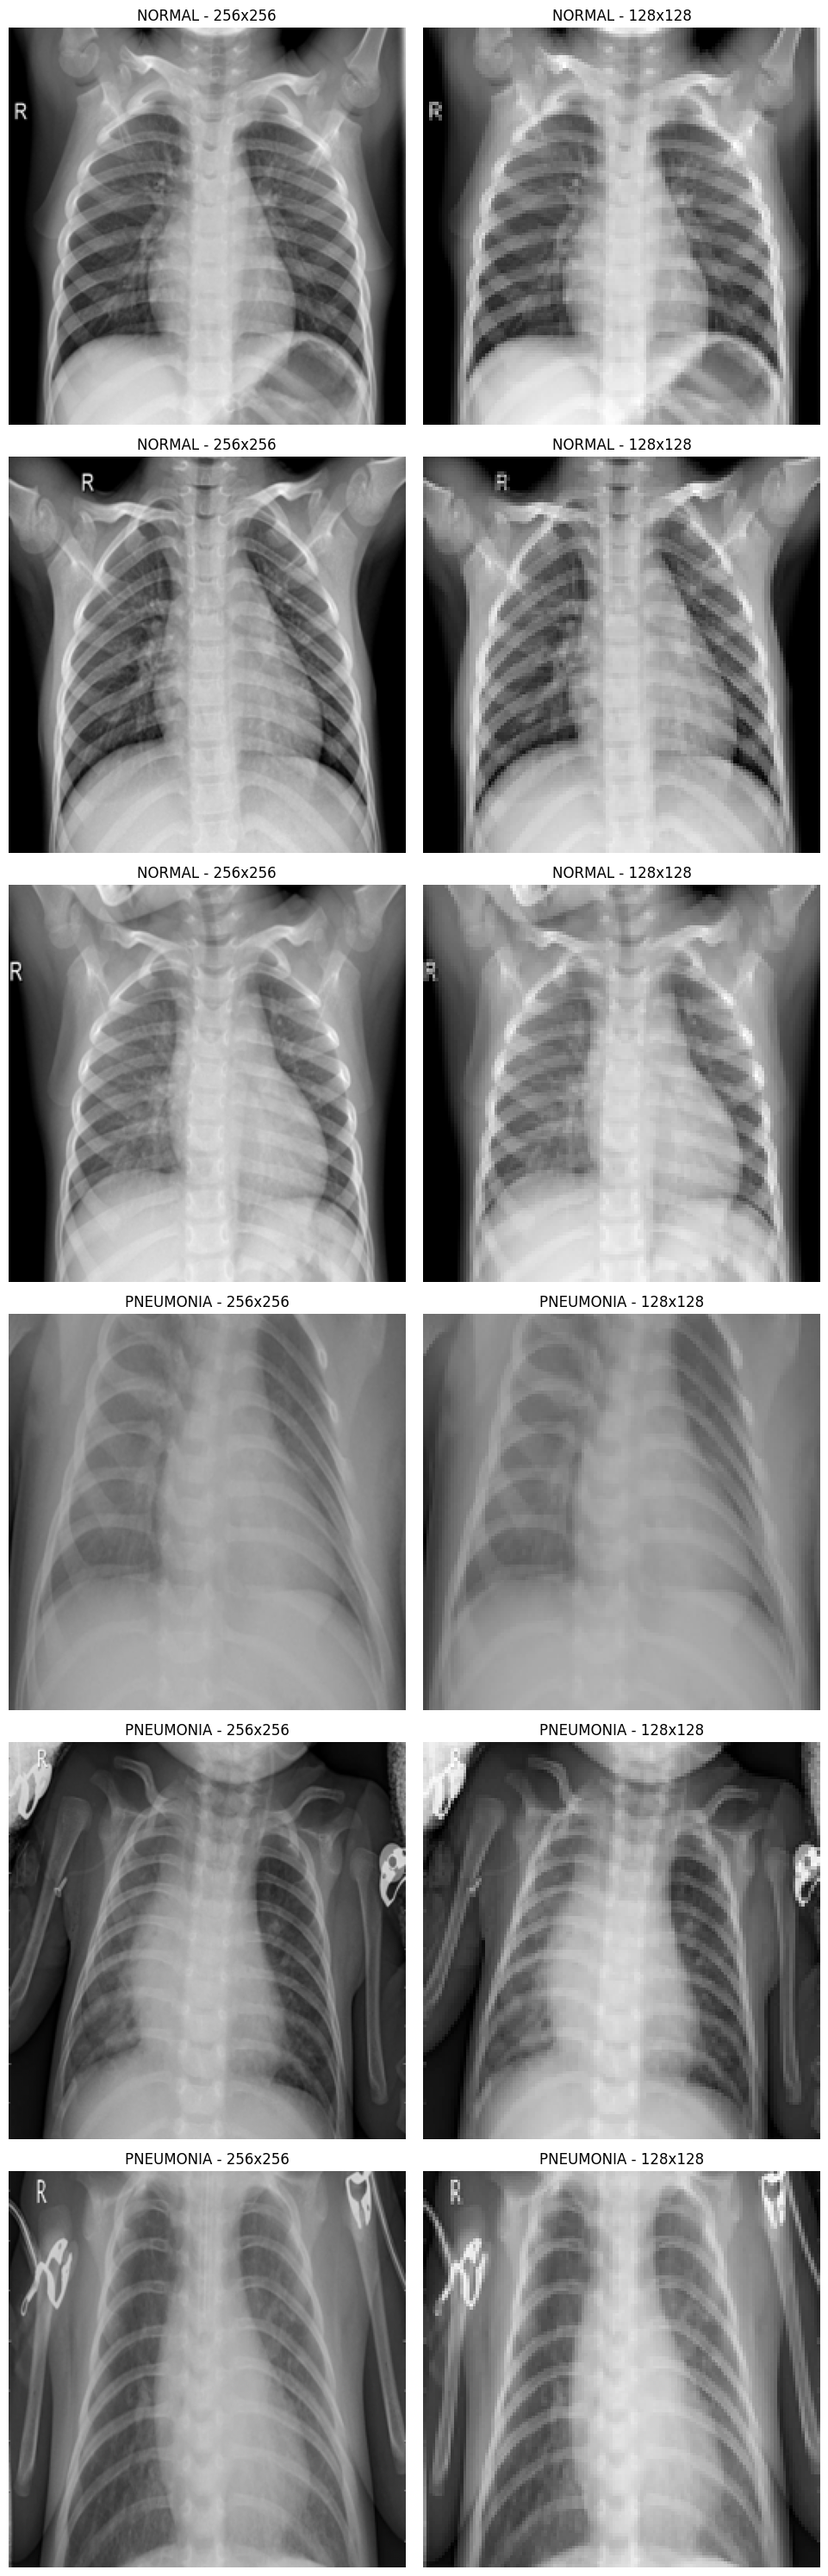

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

train_normal_path = os.path.join(base_dir, 'train', 'NORMAL')
train_pneumonia_path = os.path.join(base_dir, 'train', 'PNEUMONIA')

random.seed(42)
sample_normal = random.sample(os.listdir(train_normal_path), 3)
sample_pneumonia = random.sample(os.listdir(train_pneumonia_path), 3)

samples = [(train_normal_path, name, 'NORMAL') for name in sample_normal] + \
          [(train_pneumonia_path, name, 'PNEUMONIA') for name in sample_pneumonia]

SIZE_A = (256, 256)
SIZE_B = (128, 128)

fig, axes = plt.subplots(len(samples), 2, figsize=(10, 5 * len(samples)))

for i, (path, img_name, label) in enumerate(samples):
    img = Image.open(os.path.join(path, img_name))

    resized_a = img.resize(SIZE_A)
    resized_b = img.resize(SIZE_B)

    axes[i][0].imshow(resized_a, cmap='gray')
    axes[i][0].set_title(f'{label} - {SIZE_A[0]}x{SIZE_A[1]}')
    axes[i][0].axis('off')

    axes[i][1].imshow(resized_b, cmap='gray')
    axes[i][1].set_title(f'{label} - {SIZE_B[0]}x{SIZE_B[1]}')
    axes[i][1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
train = keras.utils.image_dataset_from_directory(
    base_dir+'/train',
    labels='inferred',
    image_size = (128,128),
    batch_size=64,
    validation_split = 0.2,
    subset= 'training',
    seed = 42,
    color_mode = 'rgb'
)
validation  = keras.utils.image_dataset_from_directory(
    base_dir+'/train',
    labels='inferred',
    image_size = (128,128),
    batch_size=64,
    validation_split = 0.2,
    subset= 'validation',
    seed = 42,
    color_mode = 'rgb'
)

test =keras.utils.image_dataset_from_directory(
    base_dir+'/test',
    labels='inferred',
    image_size = (128,128),
    batch_size=64,
    color_mode = 'rgb'
)

# Fixed: using the correct variable names 'train' and 'validation'
overlap = set(train.file_paths) & set(validation.file_paths)
print(f"عدد الصور المشتركة: {len(overlap)}")
print(f"عدد صور train: {len(train.file_paths)}")
print(f"عدد صور validation: {len(validation.file_paths)}")

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
عدد الصور المشتركة: 0
عدد صور train: 4173
عدد صور validation: 1043


In [ ]:
normalization_layer = keras.layers.Rescaling(1./255)
train = train.map(lambda x, y: (normalization_layer(x), y))
validation = validation.map(lambda x, y: (normalization_layer(x), y))
test = test.map(lambda x, y: (normalization_layer(x),y))

In [ ]:
data_augmentation = keras.Sequential(
    [
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(0.1),
        keras.layers.RandomZoom(0.1),
        keras.layers.RandomContrast(0.1)
    ]
)

In [ ]:
model = keras.Sequential([
    keras.layers.Conv2D(16, 3, padding='same', activation='relu', input_shape=(128,128,3)),
    keras.layers.MaxPool2D(2,2),
    keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(2,2),
    keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    keras.layers.MaxPool2D(2,2),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1, activation='sigmoid')
    ])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,120,993 (8.09 MB)

 Trainable params: 2,120,993 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',
              loss=keras.losses.BinaryCrossentropy(),
              metrics=['accuracy',tf.keras.metrics.Precision(),tf.keras.metrics.Recall()])

In [ ]:
EarlyStopping=EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)
ModelCheckpoint=ModelCheckpoint(
    'best_model.keras',
    monitor='val_loss',
    save_best_only=True
)


In [ ]:
model1 = model.fit(
    train,
    validation_data=validation,
    epochs=100,
    callbacks=[EarlyStopping, ModelCheckpoint]
)

Epoch 1/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1627s 22s/step - accuracy: 0.8639 - loss: 0.3064 - precision: 0.8738 - recall: 0.9533 - val_accuracy: 0.9156 - val_loss: 0.2273 - val_precision: 0.9021 - val_recall: 0.9975
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 61s 677ms/step - accuracy: 0.9514 - loss: 0.1260 - precision: 0.9657 - recall: 0.9685 - val_accuracy: 0.9616 - val_loss: 0.1052 - val_precision: 0.9796 - val_recall: 0.9698
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 44s 671ms/step - accuracy: 0.9672 - loss: 0.0956 - precision: 0.9792 - recall: 0.9763 - val_accuracy: 0.9674 - val_loss: 0.0962 - val_precision: 0.9726 - val_recall: 0.9849
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 684ms/step - accuracy: 0.9720 - loss: 0.0778 - precision: 0.9827 - recall: 0.9792 - val_accuracy: 0.9693 - val_loss: 0.0926 - val_precision: 0.9762 - val_recall: 0.9836
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 44s 669ms/step - accuracy: 0.9768 - loss: 0.0621 - precision: 0.9841 - recall: 0.9844 - val_accuracy: 0.9684 - va

In [ ]:
best_model = tf.keras.models.load_model('best_model.keras')

In [ ]:
test_loss, test_accuracy, test_precision, test_recall = best_model.evaluate(test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 219s 22s/step - accuracy: 0.7516 - loss: 1.7252 - precision: 0.7172 - recall: 0.9949
Test Loss: 1.7252
Test Accuracy: 0.7516
Test Precision: 0.7172
Test Recall: 0.9949


In [ ]:
resnet=ResNet50(
    input_shape=(128,128,3),
    weights='imagenet',
    include_top=False
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [ ]:
resnet.trainable = False

In [ ]:
transfer_model = keras.Sequential([
    resnet,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(1, activation='sigmoid')
])
transfer_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
transfer_model.compile(
    optimizer='adam',
    loss=keras.losses.BinaryCrossentropy(),
    metrics=['accuracy',tf.keras.metrics.Precision(),tf.keras.metrics.Recall()]
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
TEarlyStopping=EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)
TModelCheckpoint=ModelCheckpoint(
    'transfer_best_model.keras',
    monitor='val_loss',
    save_best_only=True
)

In [ ]:
model2 = transfer_model.fit(
    train,
    validation_data=validation,
    epochs=100,
    callbacks=[TEarlyStopping, TModelCheckpoint]
)

Epoch 1/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 71s 842ms/step - accuracy: 0.7168 - loss: 0.6028 - precision_1: 0.7383 - recall_1: 0.9549 - val_accuracy: 0.7613 - val_loss: 0.5451 - val_precision_1: 0.7613 - val_recall_1: 1.0000
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 46s 689ms/step - accuracy: 0.7393 - loss: 0.5509 - precision_1: 0.7394 - recall_1: 0.9990 - val_accuracy: 0.7613 - val_loss: 0.5052 - val_precision_1: 0.7613 - val_recall_1: 1.0000
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 45s 686ms/step - accuracy: 0.7426 - loss: 0.5124 - precision_1: 0.7420 - recall_1: 0.9987 - val_accuracy: 0.7632 - val_loss: 0.4635 - val_precision_1: 0.7627 - val_recall_1: 1.0000
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 46s 693ms/step - accuracy: 0.7635 - loss: 0.4724 - precision_1: 0.7627 - recall_1: 0.9867 - val_accuracy: 0.8006 - val_loss: 0.4336 - val_precision_1: 0.8046 - val_recall_1: 0.9748
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 84s 727ms/step - accuracy: 0.7891 - loss: 0.4379 - precision_1: 0.7883 - recall_1

In [ ]:
transfer_best_model = tf.keras.models.load_model('transfer_best_model.keras')

In [ ]:
tloss, ttest_accuracy, ttest_precision, ttest_recall= transfer_best_model.evaluate(test)
print(f"Test Loss: {tloss:.4f}")
print(f"Test Accuracy: {ttest_accuracy:.4f}")
print(f"Test Precision: {ttest_precision:.4f}")
print(f"Test Recall: {ttest_recall}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 520ms/step - accuracy: 0.7228 - loss: 0.8418 - precision_1: 0.6976 - recall_1: 0.9821
Test Loss: 0.8418
Test Accuracy: 0.7228
Test Precision: 0.6976
Test Recall: 0.9820512533187866


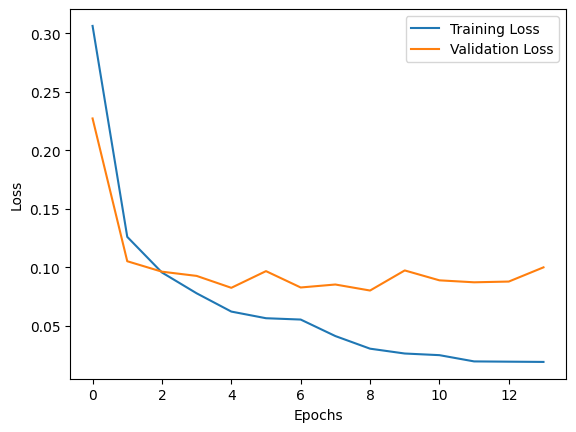

In [ ]:
plt.plot(model1.history['loss'], label='Training Loss')
plt.plot(model1.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [ ]:
type(model2)

keras.src.callbacks.history.History

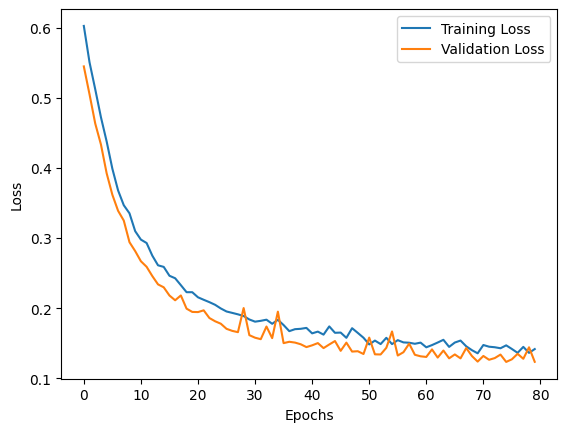

In [ ]:
plt.plot(model2.history['loss'], label='Training Loss')
plt.plot(model2.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


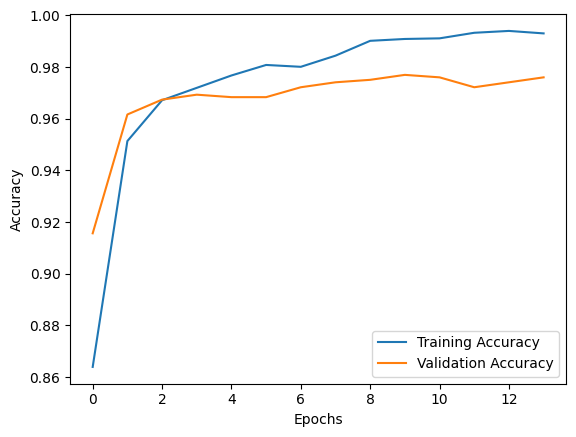

In [ ]:
plt.plot(model1.history['accuracy'], label='Training Accuracy')
plt.plot(model1.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


## Model Comparison

Here's a comparison of the test results for `model1` (the custom CNN) and `model2` (the ResNet50 transfer learning model):

| Metric        | Custom CNN (model1) | ResNet50 (model2) |
|---------------|---------------------|-------------------|
| Test Loss     | {{test_loss:.4f}}   | {{tloss:.4f}}     |
| Test Accuracy | {{test_accuracy:.4f}}| {{ttest_accuracy:.4f}}|
| Test Precision| {{test_precision:.4f}}| {{ttest_precision:.4f}}|
| Test Recall   | {{test_recall:.4f}} | {{ttest_recall:.4f}}|
